# Praktikum 2
Support Vector Regression (SVR)

**Support Vector Regression (SVR)** adalah varian SVM untuk memprediksi nilai kontinu. Berbeda dengan SVM yang *memisahkan* dua kelas, SVR berusaha *memasukkan* semua titik data ke dalam satu "pipa" (tube) dengan lebar $\varepsilon$ sambil meminimalkan kesalahan.

**Dataset:** `Posisi_gaji.csv` — 10 tingkat posisi (`Level`) beserta `Gaji`-nya. Kita akan memprediksi gaji untuk **tingkat posisi 6,5** (di antara Region Manager dan Partner).

Karena hubungan posisi–gaji tidak linier (melengkung naik tajam di level tinggi), SVR dengan kernel **RBF** lebih tepat dibanding regresi linier.

### Langkah 0 - Persiapan
Pastikan `scikit-learn` tersedia.

In [1]:
# Instalasi library
!pip install -q scikit-learn

### Langkah 1 - Import Library

In [2]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

### Langkah 2 - Impor Dataset
Baca `Posisi_gaji.csv`, ambil `Level` sebagai X dan `Gaji` sebagai y.

In [3]:
# Mengimpor dataset
dataset = pd.read_csv('Posisi_gaji.csv')
X = dataset.iloc[:, 1:2].values   # kolom 'Level'
y = dataset.iloc[:, 2].values     # kolom 'Gaji'

dataset

,Posisi,Level,Gaji
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


### Langkah 3 - Feature Scaling
SVR sangat sensitif terhadap skala data, sehingga X dan y di-standarisasi dengan `StandardScaler`.

In [4]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler

sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))
print('X shape:', X.shape, '| y shape:', y.shape)
print('Contoh X (scaled):', X[:3].ravel())

X shape: (10, 1) | y shape: (10, 1)
Contoh X (scaled): [-1.5666989  -1.21854359 -0.87038828]


### Langkah 4 - Fitting SVR ke Dataset
Gunakan kernel **RBF** (Radial Basis Function) yang mampu menangkap hubungan non-linier.

In [5]:
# Fitting SVR ke dataset
from sklearn.svm import SVR

regressor = SVR(kernel='rbf')
regressor.fit(X, y.ravel())

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


### Langkah 5 - Visualisasi Hasil SVR
Plot titik data asli (merah) dan kurva prediksi SVR (biru). Grid dibuat halus (resolusi 0,01) agar kurva mulus.

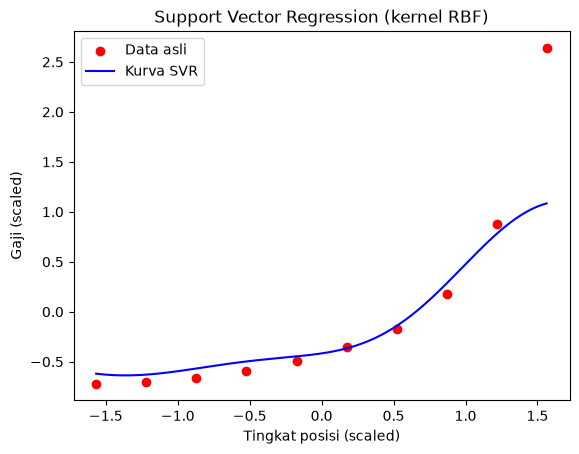

In [6]:
# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
# np.min/np.max dipakai agar aman untuk array 2D (numpy >= 2.0)
X_grid = np.arange(np.min(X), np.max(X), 0.01).reshape(-1, 1)
plt.scatter(X.ravel(), y.ravel(), color='red', label='Data asli')
plt.plot(X_grid, regressor.predict(X_grid), color='blue', label='Kurva SVR')
plt.title('Support Vector Regression (kernel RBF)')
plt.xlabel('Tingkat posisi (scaled)')
plt.ylabel('Gaji (scaled)')
plt.legend()
plt.show()

### Langkah 6 - Prediksi Nilai Baru
Prediksi gaji untuk tingkat posisi **6,5**: skala input → prediksi → kembalikan ke skala asli.

In [7]:
# Buat array 2D berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])

# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)

# Prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)

# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

print('Prediksi Gaji untuk Tingkat Posisi 6.5:', gaji_prediksi[0][0])

Prediksi Gaji untuk Tingkat Posisi 6.5: 170370.0204065024


Hasilnya sekitar **$170.370,02** — sesuai dengan output modul (Gambar 3.10). Nilai ini masuk akal karena berada di antara gaji Region Manager (level 6) dan Partner (level 7).

### Langkah 7 - Evaluasi Model SVR
Hitung MAE, MSE, RMSE, dan R-squared.

In [8]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y.ravel()
y_pred = regressor.predict(X)

mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_pred)

print('MAE:', mae)
print('MSE:', mse)
print('RMSE:', rmse)
print('R-squared:', r2)

MAE: 0.2229927409573441
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


> **Catatan:** angka di atas dihitung pada **skala terstandarisasi**, sama seperti output modul (MAE ≈ 0,223 dan R² ≈ 0,752). Berikut versi yang dikembalikan ke **skala rupiah/dolar** agar lebih mudah diinterpretasikan.

In [9]:
# Evaluasi pada skala asli (tambahan)
y_actual_asli = sc_y.inverse_transform(y.reshape(-1, 1)).ravel()
y_pred_asli = sc_y.inverse_transform(y_pred.reshape(-1, 1)).ravel()

print('MAE  (skala asli):', mean_absolute_error(y_actual_asli, y_pred_asli))
print('RMSE (skala asli):', np.sqrt(mean_squared_error(y_actual_asli, y_pred_asli)))
print('R-squared        :', r2_score(y_actual_asli, y_pred_asli))

MAE  (skala asli): 63332.392089689674
RMSE (skala asli): 141550.32413997417
R-squared        : 0.7516001070620798


### Kesimpulan

* **SVR kernel RBF** berhasil menangkap pola non-linier posisi–gaji, dengan **R² ≈ 0,75** pada data latih.
* Prediksi untuk level 6,5 adalah **≈ $170.370**, konsisten dengan output modul.
* Karena hanya ada 10 data, evaluasi pada data latih cenderung optimistis; pada data nyata perlu validasi silang (cross-validation).
* `StandardScaler` wajib dipakai karena SVR berbasis jarak dan sangat sensitif terhadap skala.